In [1]:
import os
import subprocess
import time
from pathlib import Path


def setup_headless_vtk(
    width=1920,
    height=1080,
    depth=24,
    start_display=90,
    end_display=200,
):
    """
    Start a private Xvfb server and configure VTK/PyVista
    for software rendering on HPC systems.
    """

    # If a valid DISPLAY already exists, keep it
    if os.environ.get("DISPLAY"):
        print(f"Using existing DISPLAY={os.environ['DISPLAY']}")
        return os.environ["DISPLAY"]

    # Find an unused display number
    display_num = None

    for d in range(start_display, end_display):
        lock_file = Path(f"/tmp/.X{d}-lock")

        if lock_file.exists():
            continue

        proc = subprocess.Popen(
            [
                "Xvfb",
                f":{d}",
                "-screen",
                "0",
                f"{width}x{height}x{depth}",
            ],
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL,
        )

        # Give Xvfb a moment to start
        time.sleep(1)

        if proc.poll() is None:
            display_num = d
            break

    if display_num is None:
        raise RuntimeError("Could not find a free X display")

    display = f":{display_num}"

    # Configure rendering environment
    os.environ["DISPLAY"] = display
    os.environ["VTK_DEFAULT_OPENGL_WINDOW"] = "vtkXOpenGLRenderWindow"
    os.environ["LIBGL_ALWAYS_SOFTWARE"] = "1"
    os.environ["MESA_LOADER_DRIVER_OVERRIDE"] = "llvmpipe"

    print(f"Started Xvfb on DISPLAY={display}")

    return display

setup_headless_vtk()

Started Xvfb on DISPLAY=:90


':90'

In [2]:
import pyvista as pv
pv.set_jupyter_backend("html")

import mne
mne.viz.set_3d_backend("notebook")

import matplotlib.pyplot as plt


Using notebook 3d backend.


In [3]:
from mri import plot_subj, plot_subjs_on_avg

# Subject-specific

In [4]:
# brain = plot_subj(
#     'S86',
#     surface='pial',
#     brain_kwargs={
#         'cortex': [0.900, 0.900, 0.900],
#         # 'cortex': 'ivory',
#         'alpha': 0.7,
#         'background': 'white',
#         'show': False,
#     },
#     elec_kwargs={
#         'color': 'red',
#         'scale_factor': 0.05,
#         'micro_scale_factor': 1.3,
#         'map_surface': None},
# )
# brain.show_view('lateral')
# brain._renderer.plotter.show(jupyter_backend='html')

In [5]:
# # brain.show_view('frontal', azimuth=95, elevation=95)
# brain.show_view('lateral')
# img = brain.screenshot()

# fig = plt.figure(figsize=(8,8))
# ax = fig.add_subplot(111)
# ax.imshow(img)
# ax.axis('off')

# plt.show()

# On average subject

In [6]:
brain = plot_subjs_on_avg(
    ['S83', 'S86'],
    # ['S86'],
    # method='talairach',
    surface='pial',
    brain_kwargs={
        'cortex': [0.900, 0.900, 0.900],
        # 'cortex': 'ivory',
        'alpha': 0.7,
        'background': 'white',
        'show': False,
    },
    elec_kwargs={
        'color': 'red',
        'scale_factor': 0.05,
        'micro_scale_factor': 1.3,
        'map_surface': None},
)
brain.show_view('lateral')
brain._renderer.plotter.show(jupyter_backend='html')

EmbeddableWidget(value='<iframe srcdoc="<!DOCTYPE html>\n<html>\n  <head>\n    <meta http-equiv=&quot;Content-…

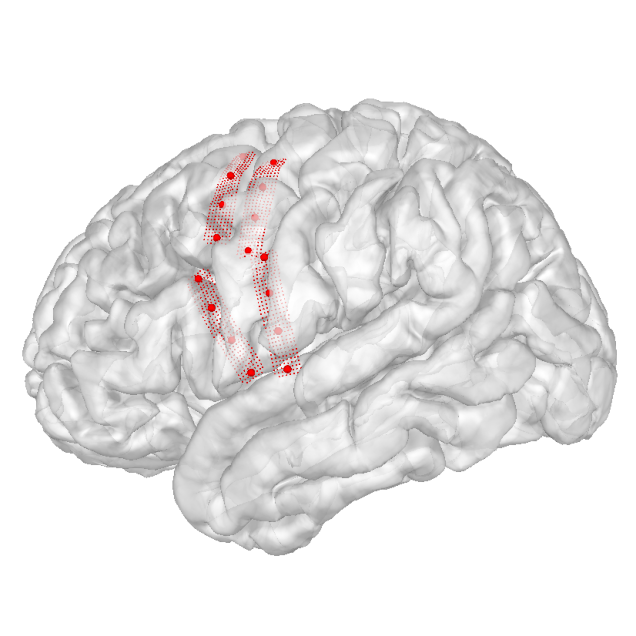

In [18]:
img = brain.screenshot()

fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111)
ax.imshow(img)
ax.axis('off')

plt.show()